# Pneumonia detection — corrected pipeline
Fixes vs. the original notebook:
1. **Evaluation bug**: single-logit head was decoded with `argmax(dim=1)` (always 0). Now `sigmoid(logit) >= threshold`.
2. **Silent empty NIH set**: only NIH metadata was downloaded, no images, so training used Guangzhou only. Now NIH comes from a small streamed subset (`prepare_nih_subset.py`, ~2.5 GB streamed instead of 45 GB downloaded) and the loader fails loudly if it is missing.
3. **Validation used training augmentation**: now separate train / eval transforms.
4. **Image-level random split**: now patient-level, source-stratified train/val/test.
5. **Source confound**: each source must contain both classes; metrics are reported per source.
6. **Imbalance**: `pos_weight`, AUROC-based model selection, threshold chosen on val (not test).
7. **No hard-coded Kaggle token.** Revoke the one that was in the old notebook.


In [9]:
# Installs anything missing into THIS notebook's kernel environment, then asks for a restart.
import importlib.util
from IPython import get_ipython
needed = {"numpy": "numpy", "pandas": "pandas", "cv2": "opencv-python", "torch": "torch", "torchvision": "torchvision",
          "sklearn": "scikit-learn", "datasets": "datasets", "PIL": "pillow", "matplotlib": "matplotlib"}
missing = [pip for mod, pip in needed.items() if importlib.util.find_spec(mod) is None]
if missing:
    get_ipython().run_line_magic("pip", "install " + " ".join(missing))
    print("Installed:", missing, "-> now RESTART the kernel (Restart button in the toolbar) and run from the top.")
else:
    print("All packages present.")

All packages present.


In [10]:
import os, re, sys, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
from IPython import get_ipython

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)  # cpu works locally but is slow: use DEBUG_FRAC and fewer epochs, or a GPU

device: cpu


In [11]:
# ---- PATHS --------------------------------------------------------------------
# Guangzhou: already downloaded.  NIH: small balanced subset streamed from Hugging Face.
GZ_ROOT  = Path("C:/Machine Learning/[DATASET] chest_xray")   # must contain train/ val/ test/
NIH_DIR  = Path("nih_subset")
NIH_META = NIH_DIR / "metadata.csv"

assert (GZ_ROOT / "train" / "NORMAL").exists(), f"Guangzhou folder not found or wrong level: {GZ_ROOT}"

if not NIH_META.exists():
    # streams ~2.5 GB from Hugging Face, keeps ~2000 images (tens of MB). Needs: pip install datasets pillow
    get_ipython().system(f'"{sys.executable}" prepare_nih_subset.py --per-class 1000 --out nih_subset')
print("Guangzhou found:", GZ_ROOT.exists(), "| NIH subset found:", NIH_META.exists())

Guangzhou found: True | NIH subset found: True


In [12]:
# ---- BUILD ONE DATAFRAME: path, label, source, patient ------------------------
def gz_patient(name):
    m = re.search(r"person(\d+)", name)
    if m: return "gzP_" + m.group(1)
    m = re.search(r"IM-(\d{4})", name)          # NORMAL files: IM-0115-0001.jpeg, NORMAL2-IM-0373-0001-0001.jpeg
    return "gzN_" + (m.group(1) if m else Path(name).stem)

rows = []
for split in ["train", "val", "test"]:
    for cat, lab in [("NORMAL", 0), ("PNEUMONIA", 1)]:
        for p in (GZ_ROOT / split / cat).glob("*.jpeg"):
            rows.append(dict(path=str(p), label=lab, source="guangzhou", patient=gz_patient(p.name)))
df_gz = pd.DataFrame(rows)
print("Guangzhou images found:", len(df_gz), "(the full dataset has 5856)")
assert len(df_gz) > 0, "no Guangzhou images found, check GZ_ROOT"

# NIH subset written by prepare_nih_subset.py (label 1 = Pneumonia, 0 = No Finding only)
if NIH_META.exists():
    nih = pd.read_csv(NIH_META)
    nih["path"] = nih["path"].apply(lambda p: str(NIH_DIR / p))
    nih["patient"] = "nih_" + nih["patient_id"].astype(str)
    nih["source"] = "nih"
else:
    print("!!! NIH subset missing:", NIH_META)
    nih = pd.DataFrame(columns=["label", "path", "patient", "source"])
n_pos, n_neg = (nih.label == 1).sum(), (nih.label == 0).sum()
print(f"NIH images on disk: pneumonia={n_pos}, no-finding={n_neg}")
if min(n_pos, n_neg) < 50:
    print("!!! WARNING: NIH has (almost) no usable images on disk. Training on Guangzhou ONLY. !!!")
    df_nih = nih.iloc[0:0]
else:
    k = min(n_pos, n_neg, 1500)   # balanced classes *within* NIH so source != label
    df_nih = pd.concat([nih[nih.label == c].sample(k, random_state=SEED) for c in (0, 1)])

df = pd.concat([df_gz, df_nih[["path","label","source","patient"]]], ignore_index=True)
df["strata"] = df.source + "_" + df.label.astype(str)
print(pd.crosstab(df.source, df.label))   # LOOK AT THIS. Each source should have both classes.

DEBUG_FRAC = 1.0   # set e.g. 0.1 for a fast smoke test on CPU, then back to 1.0
if DEBUG_FRAC < 1.0:
    df = df.groupby("strata", group_keys=False).sample(frac=DEBUG_FRAC, random_state=SEED).reset_index(drop=True)
    print("DEBUG subset:", len(df), "images")

Guangzhou images found: 5855 (the full dataset has 5856)
NIH images on disk: pneumonia=1000, no-finding=1000
label         0     1
source               
guangzhou  1583  4272
nih        1000  1000


In [13]:
# ---- PATIENT-LEVEL, SOURCE+CLASS STRATIFIED SPLIT (~70/15/15) -----------------
def group_split(d, n_splits):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    a, b = next(sgkf.split(d, d.strata, d.patient))
    return d.iloc[a].reset_index(drop=True), d.iloc[b].reset_index(drop=True)

trainval, test = group_split(df, 7)
train, val     = group_split(trainval, 6)
for a, b in [(train, val), (train, test), (val, test)]:
    assert not set(a.patient) & set(b.patient), "patient leakage between splits"
TRAIN_SOURCES = ["guangzhou", "nih"]   # external-validation runs: ["guangzhou"] or ["nih"] (see the notes cell at the end)
train = train[train.source.isin(TRAIN_SOURCES)].reset_index(drop=True)   # test keeps ALL sources
val   = val[val.source.isin(TRAIN_SOURCES)].reset_index(drop=True)       # val too, so the threshold never sees the held-out source
for n, d in [("train", train), ("val", val), ("test", test)]:
    print(n, len(d), "| pneumonia rate:", round(d.label.mean(), 3), "|", d.source.value_counts().to_dict())

train 5591 | pneumonia rate: 0.667 | {'guangzhou': 4157, 'nih': 1434}
val 1177 | pneumonia rate: 0.705 | {'guangzhou': 890, 'nih': 287}
test 1087 | pneumonia rate: 0.655 | {'guangzhou': 808, 'nih': 279}


In [14]:
# ---- DATASET / LOADERS --------------------------------------------------------
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([transforms.ToPILImage(),
                               transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
                               transforms.RandomRotation(10),
                               transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf  = transforms.Compose([transforms.ToPILImage(), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

CLAHE_FIRST = True   # True = what the first training run used: CLAHE at original resolution, then resize.
                     # False = resize first, then CLAHE (same operation on the same input size for every source).
SQUARE_CROP = False  # True = cut a centre square (side = shorter edge) BEFORE anything else. Removes the class-dependent
                     # squash, the black side borders and most side markers. COST: wide frames (aspect 1.4-1.5) lose
                     # 15-17% of the width on each side, which can clip peripheral lung. Look at the crops first.
def load_and_preprocess(path):
    """grayscale -> [optional centre-square crop] -> CLAHE / resize (order set by CLAHE_FIRST) -> 3 identical channels (uint8 HxWx3). The ONE place preprocessing lives."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None: raise FileNotFoundError(path)
    if SQUARE_CROP:
        h, w = img.shape
        side = min(h, w); y0, x0 = (h - side) // 2, (w - side) // 2
        img = img[y0:y0 + side, x0:x0 + side]
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    if CLAHE_FIRST:
        img = cv2.resize(clahe.apply(img), (224, 224), interpolation=cv2.INTER_AREA)
    else:
        img = clahe.apply(cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA))
    return np.stack([img] * 3, axis=-1)

class XRayDS(Dataset):
    def __init__(self, d, tf):
        self.paths, self.labels, self.tf = d.path.tolist(), d.label.astype("float32").tolist(), tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(load_and_preprocess(self.paths[i])), torch.tensor(self.labels[i])

NUM_WORKERS = 0 if os.name == "nt" else 4   # notebook-defined Datasets cannot be pickled by Windows worker processes
kw = dict(batch_size=32, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
train_loader = DataLoader(XRayDS(train, train_tf), shuffle=True,  **kw)
val_loader   = DataLoader(XRayDS(val,   eval_tf),  shuffle=False, **kw)   # NO augmentation
test_loader  = DataLoader(XRayDS(test,  eval_tf),  shuffle=False, **kw)

## Preprocessing checks (run before training)
Every image goes through `load_and_preprocess`: grayscale, (optional centre-square crop, off by default: `SQUARE_CROP`), CLAHE (local contrast) and resize to 224x224 in the order set by `CLAHE_FIRST`, copy to 3 channels. Then `eval_tf` (to tensor in [0,1], ImageNet mean/std normalisation) or `train_tf` (random crop and rotation first). The three cells below test that exact code: a picture grid to eyeball, numeric sanity checks, and a test of whether simple image statistics can separate sources or labels.


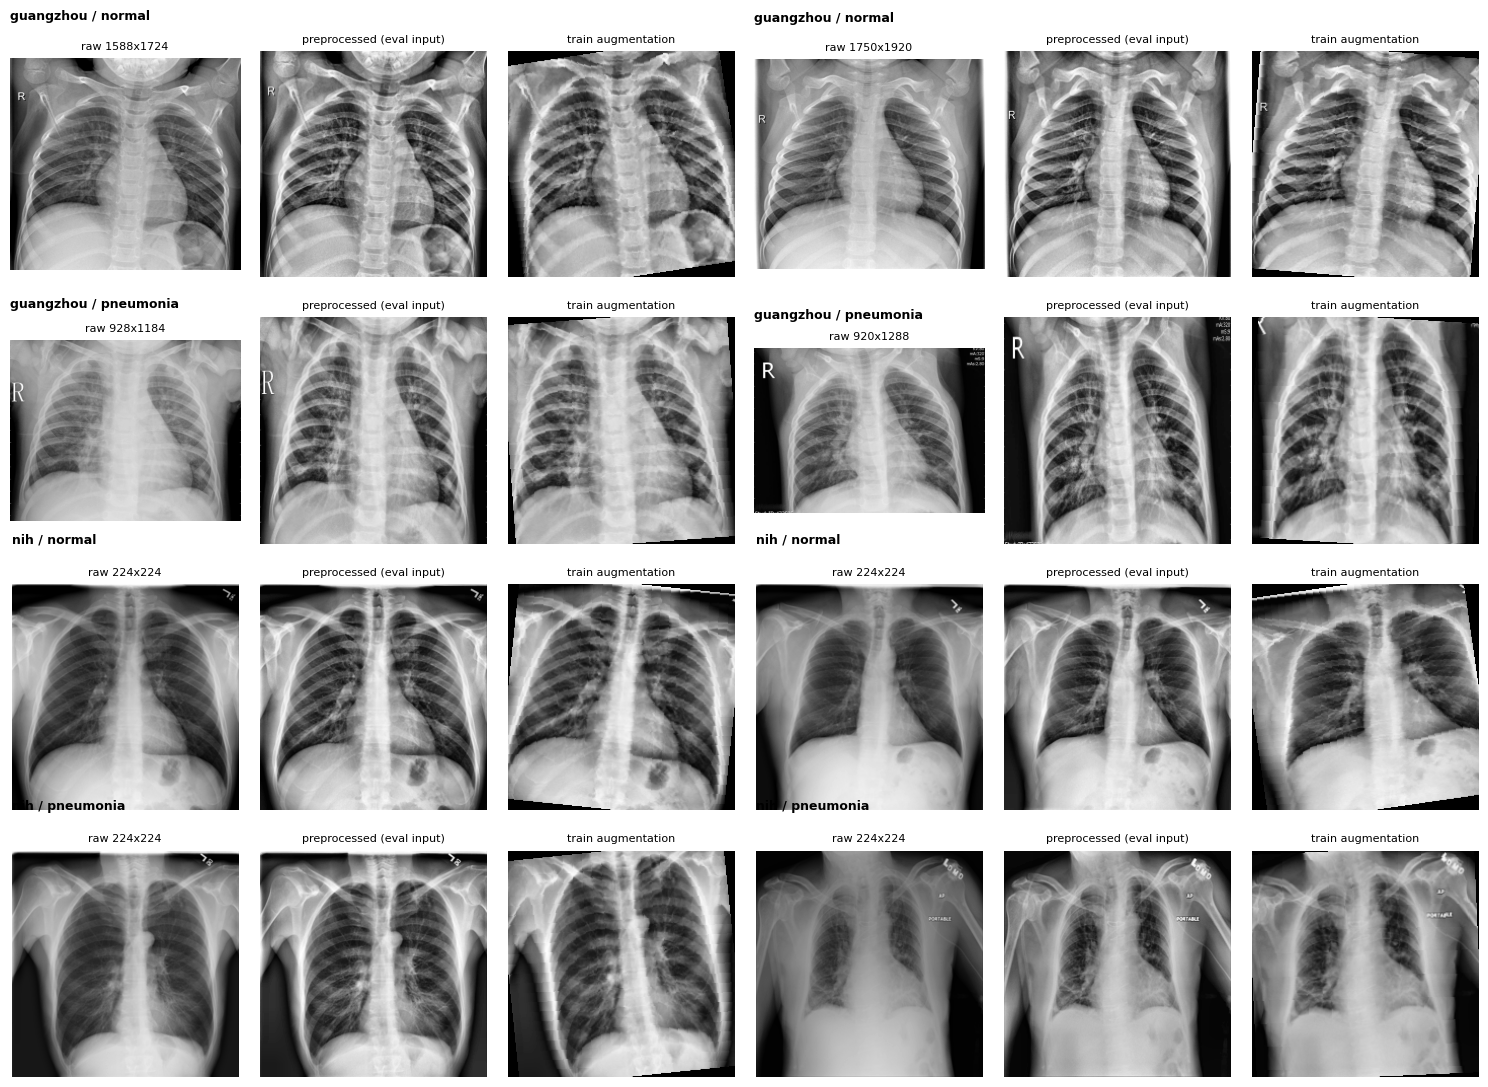

In [15]:
# ---- LOOK AT IT: raw vs preprocessed vs augmented, one row per source x class ------
import matplotlib.pyplot as plt
MEAN_T, STD_T = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)

combos = sorted(df.groupby(["source", "label"]).groups.keys())
fig, axes = plt.subplots(len(combos), 6, figsize=(15, 2.7 * len(combos)), squeeze=False)
rng = np.random.default_rng(1)
for r, (src, lab) in enumerate(combos):
    sub = df[(df.source == src) & (df.label == lab)]
    for k in range(2):
        row = sub.iloc[int(rng.integers(len(sub)))]
        raw = cv2.imread(row.path, cv2.IMREAD_GRAYSCALE)
        prep = load_and_preprocess(row.path)                                   # exactly what the Dataset uses
        aug = (train_tf(prep) * STD_T + MEAN_T).clamp(0, 1)[0].numpy()        # one random training augmentation
        panels = [(raw, f"raw {raw.shape[0]}x{raw.shape[1]}", 255),
                  (prep[..., 0], "preprocessed (eval input)", 255),
                  (aug, "train augmentation", 1)]
        for c, (im, title, vmax) in enumerate(panels):
            ax = axes[r, 3 * k + c]
            ax.imshow(im, cmap="gray", vmin=0, vmax=vmax); ax.set_title(title, fontsize=8); ax.axis("off")
        axes[r, 3 * k].text(0, 1.18, f"{src} / {'pneumonia' if lab else 'normal'}", transform=axes[r, 3 * k].transAxes,
                            fontsize=9, weight="bold")
plt.tight_layout(); plt.savefig("preprocessing_check.png", dpi=110); plt.show()

In [16]:
# ---- NUMERIC SANITY CHECKS ON THE REAL PIPELINE -------------------------------------
chk = df.sample(min(64, len(df)), random_state=0).reset_index(drop=True)
ds_eval, ds_aug = XRayDS(chk, eval_tf), XRayDS(chk, train_tf)
X = torch.stack([ds_eval[i][0] for i in range(len(ds_eval))])
lo = min((0 - m) / s for m, s in zip(MEAN, STD)); hi = max((1 - m) / s for m, s in zip(MEAN, STD))
print("shape", tuple(X.shape), "| dtype", X.dtype)
print("value range:", round(X.min().item(), 2), "to", round(X.max().item(), 2), "| legal range:", round(lo, 2), "to", round(hi, 2))
assert X.shape[1:] == (3, 224, 224) and X.dtype == torch.float32
assert X.min() >= lo - 1e-3 and X.max() <= hi + 1e-3, "pixel values outside the legal range: scaling bug"
assert X.std() > 0.2, "images are nearly constant: check loading"
print("eval transform deterministic:", torch.equal(ds_eval[0][0], ds_eval[0][0]))
print("train transform random      :", not torch.equal(ds_aug[0][0], ds_aug[0][0]))
print("labels returned match dataframe:", all(int(ds_eval[i][1]) == int(chk.label[i]) for i in range(len(chk))))
print("\nstatistics of what the network actually receives, per source:")
for s in chk.source.unique():
    xs = X[torch.from_numpy((chk.source == s).values)]
    print(f"  {s:10s} n={len(xs):3d}  mean={xs.mean():+.2f}  std={xs.std():.2f}")

shape (64, 3, 224, 224) | dtype torch.float32
value range: -2.1 to 2.64 | legal range: -2.12 to 2.64
eval transform deterministic: True
train transform random      : True
labels returned match dataframe: True

statistics of what the network actually receives, per source:
  guangzhou  n= 49  mean=+0.24  std=1.11
  nih        n= 15  mean=+0.37  std=1.13


In [17]:
# ---- DOES THE PREPROCESSING HIDE OR EXPOSE SOURCE / LABEL SHORTCUTS? ----------------
# Simple statistics (no deep learning) of the images AFTER preprocessing. If they alone separate the classes
# WITHIN one source, especially via the border or file metadata, a network can exploit that too.
import os
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier

PCTS = [1, 5, 25, 50, 75, 95, 99]
def image_features(path):
    raw = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    g = load_and_preprocess(path)[..., 0]                                  # uint8 224x224, what the network sees
    ring = np.ones(g.shape, bool); ring[24:-24, 24:-24] = False            # outer 24-px border
    f = dict(mean=g.mean(), std=g.std(), sharp=cv2.Laplacian(g, cv2.CV_64F).var(), dark_frac=(g < 10).mean(),
             border_mean=g[ring].mean(), border_std=g[ring].std(), border_dark=(g[ring] < 10).mean(),
             raw_h=raw.shape[0], raw_w=raw.shape[1], raw_aspect=raw.shape[1] / raw.shape[0],
             file_kb=os.path.getsize(path) / 1024)
    f.update({f"p{p}": v for p, v in zip(PCTS, np.percentile(g, PCTS))})
    return f

def cv_auroc(X, y, groups, n_splits=5):
    if len(np.unique(y)) < 2: return float("nan")
    oof = np.zeros(len(y))
    for tr, te in GroupKFold(n_splits=n_splits).split(X, y, groups):
        clf = HistGradientBoostingClassifier(max_iter=150, random_state=SEED).fit(X.iloc[tr], y[tr])
        oof[te] = clf.predict_proba(X.iloc[te])[:, 1]
    return roc_auc_score(y, oof)

PER_GROUP = 250
smp = pd.concat([g.sample(min(len(g), PER_GROUP), random_state=SEED) for _, g in df.groupby(["source", "label"])], ignore_index=True)
print(f"{len(smp)} images sampled; extracting features under three preprocessing variants (a few minutes)...")

orig_cfg = (CLAHE_FIRST, SQUARE_CROP)
CONFIGS = [(True,  False, "CLAHE at original resolution, then resize  (current pipeline)"),
           (False, False, "resize first, then CLAHE"),
           (False, True,  "centre-square crop, resize, then CLAHE")]
try:
    for CLAHE_FIRST, SQUARE_CROP, desc in CONFIGS:
        F = pd.DataFrame([image_features(p) for p in smp.path])
        meta_cols = ["raw_h", "raw_w", "raw_aspect", "file_kb"]
        border_cols = ["border_mean", "border_std", "border_dark"]
        img_cols = [c for c in F.columns if c not in meta_cols + border_cols]
        sets = [("image stats", img_cols), ("border-only stats", border_cols), ("size/file metadata", meta_cols)]
        print("\n=== " + desc + " ===")
        if smp.source.nunique() > 1:
            ysrc = (smp.source == "nih").astype(int).values
            print("A) can simple statistics tell the SOURCE apart?  (AUROC, 0.5 = no)")
            for name, cols in sets:
                print(f"     {name:20s} {cv_auroc(F[cols], ysrc, smp.patient.values):.3f}")
        print("B) within one source, can simple statistics predict the LABEL?  (AUROC, 0.5 = no)")
        for s in smp.source.unique():
            m = (smp.source == s).values
            for name, cols in sets:
                a = cv_auroc(F.loc[m, cols].reset_index(drop=True), smp.label.values[m], smp.patient.values[m])
                print(f"     {s:10s} {name:20s} {a:.3f}")
finally:
    CLAHE_FIRST, SQUARE_CROP = orig_cfg

print("\nmedian raw image properties per source:")
print(pd.concat([smp[["source"]], F[meta_cols]], axis=1).groupby("source").median().round(2))

1000 images sampled; extracting features under three preprocessing variants (a few minutes)...

=== CLAHE at original resolution, then resize  (current pipeline) ===
A) can simple statistics tell the SOURCE apart?  (AUROC, 0.5 = no)
     image stats          0.964
     border-only stats    0.825
     size/file metadata   1.000
B) within one source, can simple statistics predict the LABEL?  (AUROC, 0.5 = no)
     guangzhou  image stats          0.921
     guangzhou  border-only stats    0.821
     guangzhou  size/file metadata   0.982
     nih        image stats          0.573
     nih        border-only stats    0.532
     nih        size/file metadata   0.529

=== resize first, then CLAHE ===
A) can simple statistics tell the SOURCE apart?  (AUROC, 0.5 = no)
     image stats          0.942
     border-only stats    0.780
     size/file metadata   1.000
B) within one source, can simple statistics predict the LABEL?  (AUROC, 0.5 = no)
     guangzhou  image stats          0.915
     guan

In [18]:
# ---- MODEL / TRAIN ------------------------------------------------------------
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 1)   # one logit; classifier[0] is already Dropout
model.to(device)

pos_weight = torch.tensor([(train.label == 0).sum() / (train.label == 1).sum()], dtype=torch.float32, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
EPOCHS = 8   # val AUROC plateaued around epoch 3-4 in the first run; 4 is enough for the external-validation runs
PREP_TAG = ("_square" if SQUARE_CROP else "") + ("" if CLAHE_FIRST else "_resizefirst")   # default pipeline -> "" -> best.pt
CKPT = f"best{PREP_TAG}.pt" if len(TRAIN_SOURCES) == 2 else f"best_{TRAIN_SOURCES[0]}_only{PREP_TAG}.pt"
print("checkpoint file:", CKPT)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

@torch.no_grad()
def predict(model, loader):
    model.eval(); P, Y = [], []
    for x, y in loader:
        P.append(torch.sigmoid(model(x.to(device)).squeeze(1)).cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

best_auc = 0.0
for ep in range(EPOCHS):
    model.train(); tot, n = 0.0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device).unsqueeze(1)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward(); optimizer.step()
        tot += loss.item() * x.size(0); n += x.size(0)
    scheduler.step()
    pv, yv = predict(model, val_loader)
    auc = roc_auc_score(yv, pv)
    print(f"epoch {ep+1}/{EPOCHS} | train loss {tot/n:.4f} | val AUROC {auc:.4f} | val predicted-positive rate {(pv >= 0.5).mean():.3f}")
    if auc > best_auc:
        best_auc = auc; torch.save(model.state_dict(), CKPT)
model.load_state_dict(torch.load(CKPT, map_location=device))

checkpoint file: best.pt
epoch 1/8 | train loss 0.2152 | val AUROC 0.9618 | val predicted-positive rate 0.602
epoch 2/8 | train loss 0.1597 | val AUROC 0.9661 | val predicted-positive rate 0.594
epoch 3/8 | train loss 0.1401 | val AUROC 0.9751 | val predicted-positive rate 0.653
epoch 4/8 | train loss 0.1218 | val AUROC 0.9731 | val predicted-positive rate 0.634
epoch 5/8 | train loss 0.1017 | val AUROC 0.9696 | val predicted-positive rate 0.653
epoch 6/8 | train loss 0.0914 | val AUROC 0.9708 | val predicted-positive rate 0.635
epoch 7/8 | train loss 0.0734 | val AUROC 0.9727 | val predicted-positive rate 0.668
epoch 8/8 | train loss 0.0707 | val AUROC 0.9714 | val predicted-positive rate 0.669


<All keys matched successfully>

In [19]:
# ---- EVALUATION: threshold from VAL, report on TEST ---------------------------
print("trained on:", TRAIN_SOURCES)
pv, yv = predict(model, val_loader)
fpr, tpr, thr = roc_curve(yv, pv)
t = float(thr[np.argmax(tpr - fpr)])          # Youden's J on validation. Swap in a sensitivity target if you prefer.
print("chosen threshold:", round(t, 3))

pt, yt = predict(model, test_loader)
pred = (pt >= t).astype(int)                   # NEVER argmax on a single-logit output
print("TEST AUROC:", round(roc_auc_score(yt, pt), 4))
print("predicted-positive rate:", pred.mean().round(3), "| true-positive rate:", yt.mean().round(3))
print(confusion_matrix(yt, pred))
print(classification_report(yt, pred, target_names=["Normal", "Pneumonia"], zero_division=0))

print("\n--- per source (a big gap here = shortcut learning / domain shift) ---")
for s in test.source.unique():
    m = (test.source == s).values
    if len(np.unique(yt[m])) < 2: print(s, "only one class present, skipped"); continue
    tn, fp, fn, tp = confusion_matrix(yt[m], pred[m], labels=[0, 1]).ravel()
    print(f"{s:10s} n={m.sum():4d} AUROC={roc_auc_score(yt[m], pt[m]):.3f} sens={tp/(tp+fn):.3f} spec={tn/(tn+fp):.3f}")

trained on: ['guangzhou', 'nih']
chosen threshold: 0.4
TEST AUROC: 0.9707
predicted-positive rate: 0.643 | true-positive rate: 0.655
[[331  44]
 [ 57 655]]
              precision    recall  f1-score   support

      Normal       0.85      0.88      0.87       375
   Pneumonia       0.94      0.92      0.93       712

    accuracy                           0.91      1087
   macro avg       0.90      0.90      0.90      1087
weighted avg       0.91      0.91      0.91      1087


--- per source (a big gap here = shortcut learning / domain shift) ---
guangzhou  n= 808 AUROC=0.994 sens=0.969 spec=0.964
nih        n= 279 AUROC=0.802 sens=0.688 spec=0.766


## How much should you trust these numbers?
Three checks, in order of how much they tell you:
1. **Confidence intervals** (below): the NIH test slice is small, so its AUROC is uncertain.
2. **Shortcut diagnostic** (below): is the model using the lungs, or cues outside them?
3. **External validation** (the most informative): set `TRAIN_SOURCES = ["guangzhou"]` in the split cell, set `EPOCHS = 4`, re-run from the split cell down, and read the **nih** line in the per-source report. NIH was never seen in training or validation, so that number is true cross-dataset performance. Then do the same with `["nih"]` and read the **guangzhou** line.


In [20]:
# ---- patient-level bootstrap CIs + a source-only baseline ----------------------
def bootstrap_ci(d, y, p, thr, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    codes, keys = pd.factorize(d.patient.values)
    groups = [np.where(codes == k)[0] for k in range(len(keys))]
    res = []
    for _ in range(n_boot):
        idx = np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])
        yy, pp = y[idx], p[idx]
        if len(np.unique(yy)) < 2: continue
        pr = pp >= thr
        sens = (pr & (yy == 1)).sum() / (yy == 1).sum()
        spec = (~pr & (yy == 0)).sum() / (yy == 0).sum()
        res.append((roc_auc_score(yy, pp), sens, spec))
    return np.percentile(np.array(res), [2.5, 97.5], axis=0)

print("95% bootstrap CIs (resampling patients, not images)")
for name, m in [("all", np.ones(len(test), bool))] + [(s, (test.source == s).values) for s in test.source.unique()]:
    lo, hi = bootstrap_ci(test[m].reset_index(drop=True), yt[m], pt[m], t)
    print(f"{name:10s} n={m.sum():4d}  AUROC [{lo[0]:.3f}, {hi[0]:.3f}]  sens [{lo[1]:.3f}, {hi[1]:.3f}]  spec [{lo[2]:.3f}, {hi[2]:.3f}]")

# pooled AUROC you would get by knowing ONLY which dataset an image came from (no image content at all)
rate = train.groupby("source").label.mean()
print("\nsource-only baseline, pooled AUROC:", round(roc_auc_score(yt, test.source.map(rate).fillna(0.5).values), 3))

95% bootstrap CIs (resampling patients, not images)
all        n=1087  AUROC [0.961, 0.979]  sens [0.894, 0.945]  spec [0.850, 0.916]
guangzhou  n= 808  AUROC [0.991, 0.997]  sens [0.955, 0.981]  spec [0.937, 0.987]
nih        n= 279  AUROC [0.747, 0.857]  sens [0.587, 0.778]  spec [0.703, 0.831]

source-only baseline, pooled AUROC: 0.618


In [21]:
# ---- shortcut diagnostic: does the model still "see" pneumonia when the lungs are hidden? ----
# Not proof either way (the model never trained on masked images). But if within-source AUROC stays far above 0.5
# with the chest centre hidden, the model is using cues outside the lungs (borders, markers, dataset style).
@torch.no_grad()
def predict_masked(model, loader, mode):
    model.eval(); P = []
    for x, _ in loader:
        x = x.clone(); a, b = 40, 184                     # central 144x144 of the 224x224 image
        if mode == "hide_center":
            x[:, :, a:b, a:b] = 0
        else:                                             # "center_only": hide everything except the centre
            keep = x[:, :, a:b, a:b].clone(); x.zero_(); x[:, :, a:b, a:b] = keep
        P.append(torch.sigmoid(model(x.to(device)).squeeze(1)).cpu())
    return torch.cat(P).numpy()

for mode in ["hide_center", "center_only"]:
    pm = predict_masked(model, test_loader, mode)
    per = " | ".join(f"{s}: {roc_auc_score(yt[(test.source == s).values], pm[(test.source == s).values]):.3f}" for s in test.source.unique())
    print(f"{mode:12s} pooled AUROC={roc_auc_score(yt, pm):.3f} | {per}")

hide_center  pooled AUROC=0.684 | guangzhou: 0.661 | nih: 0.554
center_only  pooled AUROC=0.862 | guangzhou: 0.863 | nih: 0.783
